In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

files.upload()  # selecione o creditcard.csv de data/raw
df = pd.read_csv("creditcard.csv")
print(df.shape)

Saving creditcard.csv to creditcard.csv
(284807, 31)


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["Class"])
y = df["Class"]

# 60% treino, 20% validação, 20% teste, mantendo a proporção de fraudes
X_tmp, X_teste, y_tmp, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42
)

# Guarda o valor original da transação na validação (usaremos no cálculo de custo)
valor_val = X_val["Amount"].to_numpy().copy()

# Escalonamento ajustado só no treino
scaler = StandardScaler().fit(X_treino[["Amount", "Time"]])
X_treino = X_treino.copy()
X_val = X_val.copy()
X_teste = X_teste.copy()
for conj in (X_treino, X_val, X_teste):
    conj[["Amount", "Time"]] = scaler.transform(conj[["Amount", "Time"]])

print("Treino:", X_treino.shape, "fraudes:", y_treino.sum())
print("Validação:", X_val.shape, "fraudes:", y_val.sum())
print("Teste:", X_teste.shape, "fraudes:", y_teste.sum())

Treino: (170883, 30) fraudes: 295
Validação: (56962, 30) fraudes: 99
Teste: (56962, 30) fraudes: 98


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

logreg = LogisticRegression(class_weight="balanced", max_iter=1000)
logreg.fit(X_treino, y_treino)

prob_logreg = logreg.predict_proba(X_val)[:, 1]
pr_auc_logreg = average_precision_score(y_val, prob_logreg)
print(f"PR-AUC (regressão logística): {pr_auc_logreg:.4f}")

PR-AUC (regressão logística): 0.6831


In [11]:
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score

lgbm = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    random_state=42,
    verbose=-1,
)
lgbm.fit(X_treino, y_treino)

prob_lgbm = lgbm.predict_proba(X_val)[:, 1]
pr_auc_lgbm = average_precision_score(y_val, prob_lgbm)
print(f"PR-AUC (LightGBM): {pr_auc_lgbm:.4f}")

PR-AUC (LightGBM): 0.7682


In [12]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=200, contamination=0.0017, random_state=42)
iso.fit(X_treino)

# score_samples dá valores altos para transações normais; invertemos o sinal
score_iso = -iso.score_samples(X_val)
pr_auc_iso = average_precision_score(y_val, score_iso)
print(f"PR-AUC (Isolation Forest): {pr_auc_iso:.4f}")

PR-AUC (Isolation Forest): 0.1158


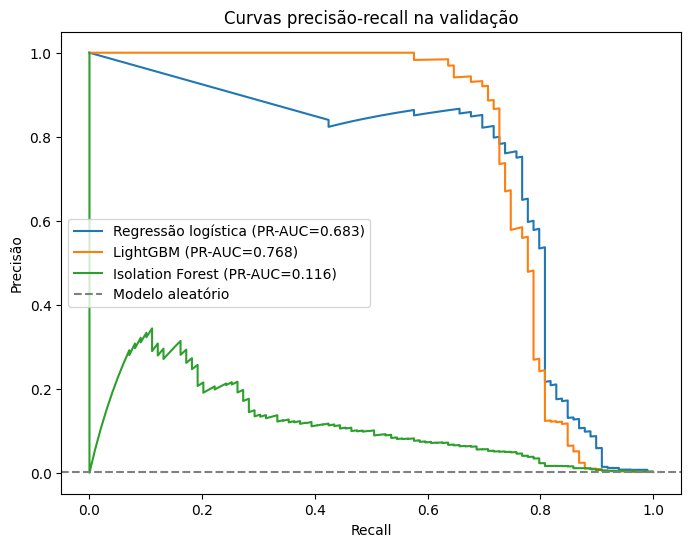

In [13]:
from sklearn.metrics import precision_recall_curve

modelos = {
    f"Regressão logística (PR-AUC={pr_auc_logreg:.3f})": prob_logreg,
    f"LightGBM (PR-AUC={pr_auc_lgbm:.3f})": prob_lgbm,
    f"Isolation Forest (PR-AUC={pr_auc_iso:.3f})": score_iso,
}

plt.figure(figsize=(8, 6))
for nome, prob in modelos.items():
    precisao, recall, _ = precision_recall_curve(y_val, prob)
    plt.plot(recall, precisao, label=nome)

plt.axhline(y_val.mean(), color="gray", linestyle="--", label="Modelo aleatório")
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curvas precisão-recall na validação")
plt.legend()
plt.show()

In [14]:
import joblib

# Escolhe o melhor modelo supervisionado pelo PR-AUC na validação
if pr_auc_lgbm >= pr_auc_logreg:
    modelo_final, nome_final = lgbm, "lightgbm"
else:
    modelo_final, nome_final = logreg, "logistica"

print("Modelo escolhido:", nome_final)

# Salva as probabilidades de validação para usar no notebook 03 (limiar por custo)
prob_val_final = modelo_final.predict_proba(X_val)[:, 1]
np.save("prob_val.npy", prob_val_final)
np.save("valor_val.npy", valor_val)
np.save("y_val.npy", y_val.to_numpy())

joblib.dump(modelo_final, f"modelo_{nome_final}.joblib")
files.download(f"modelo_{nome_final}.joblib")

Modelo escolhido: lightgbm


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>